[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/timeseries/03-baselines.ipynb)

# Baselines: The Forecasts to Beat

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Set up a rolling-origin test in which a forecaster can only see the past.</li>
<li>Compute naive, seasonal-naive and seasonal-average baselines and rank them with MAE, RMSE and MASE.</li>
<li>Explain why a baseline tuned on the test window gives an optimistic score.</li>
<li>Break forecast error down by weekday and hour to see where a forecast fails.</li>
</ul>
</div>

**Prerequisites:** Pages 1 and 2 of this track. **Dataset:** NYC Taxi (Jan to Mar 2023). **Time:** about 35 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import forecasting as fc, style
from mlp_data.timeseries import taxi_hourly

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

The dispatch team asks for one thing: **at midnight, a forecast of pickups for each of the next 24 hours**. Before building anything clever, we need two things. First, a precise *protocol* for testing a forecast so that nobody, including us, can cheat. Second, a set of **baselines**: very simple forecasts that any real model has to beat. If a sophisticated model cannot beat "same as last week", it is not worth running.

We use the January to March 2023 hourly series. The last two weeks (18 to 31 March) are held back for testing.

In [2]:
y = taxi_hourly(["2023-01", "2023-02", "2023-03"]).asfreq("h").interpolate()

HORIZON = 24                                              # forecast the next 24 hours...
test_origins = fc.rolling_origins(y.index, first_origin="2023-03-18")     # ...from each midnight in the last 14 days
train = y[:"2023-03-17"]                                  # everything before the first test origin
print(f"{len(test_origins)} forecast origins, {len(test_origins) * HORIZON} forecast values to score")
print("first origin:", test_origins[0], "| last origin:", test_origins[-1])

14 forecast origins, 336 forecast values to score
first origin: 2023-03-18 00:00:00 | last origin: 2023-03-31 00:00:00


## 1. The protocol: a rolling-origin test

At each **origin** (a midnight) the forecaster may look at the history strictly *before* the origin and must predict the next 24 hours. Then the clock moves on one day and we repeat. This mimics how the forecast will really be used: every night, with the data that exists that night. `fc.backtest` enforces it: it hands the forecaster only the past, and the unit tests in the repository check that.

A **forecaster** here is any function `f(history, target_times)` that returns one number per target time. Our baselines are one-liners.

In [3]:
baselines = {
    "naive: repeat the last value": lambda hist, idx: fc.seasonal_naive(hist, idx, 1),
    "seasonal naive: same hour yesterday": lambda hist, idx: fc.seasonal_naive(hist, idx, 24),
    "seasonal naive: same hour last week": lambda hist, idx: fc.seasonal_naive(hist, idx, 168),
    "average of the same hour in the last 4 weeks": lambda hist, idx: fc.seasonal_mean(hist, idx, weeks=4),
}
runs = {name: fc.backtest(y, f, origins=test_origins, horizon=HORIZON) for name, f in baselines.items()}
scores = pd.DataFrame({name: fc.score(bt, train) for name, bt in runs.items()}).T
scores.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "sMAPE": "{:.1%}", "MASE": "{:.2f}"})

,MAE,RMSE,sMAPE,MASE
naive: repeat the last value,"2,472","2,870",66.6%,7.16
seasonal naive: same hour yesterday,704,"1,079",22.4%,2.04
seasonal naive: same hour last week,372,510,9.5%,1.08
average of the same hour in the last 4 weeks,277,381,7.1%,0.80


**How to read the metrics.** *MAE* (mean absolute error) is in the units we care about: pickups per hour. *RMSE* punishes large misses more. *sMAPE* is a percentage error. *MASE* divides the MAE by the error that "same hour last week" made on the *training* period, so 1.0 means "as good as that baseline did historically" and anything below 1 is better. (The next-but-three page explains why percentage errors are risky; here they are a rough guide.)

The ranking is a staircase, and each step teaches something:

1. **Repeating the last value** is hopeless for a day-ahead forecast (MASE above 7): the series swings by thousands within a day, so "now" says little about "twelve hours from now". It is the right baseline for series *without* a cycle, such as a stock price, and the wrong one here.
2. **Same hour yesterday** removes the daily cycle, but is still poor.
3. **Same hour last week** respects the weekly cycle too and cuts the error roughly in half again.
4. **Averaging the last four weeks** is better still: one week's values are noisy (a rainy Tuesday, a holiday), and averaging four of them smooths the noise.

So **a four-week seasonal average is the number to beat**: roughly 280 pickups an hour of error, about 7% in sMAPE.

In [4]:
assert list(scores["MAE"].round(0)) == sorted(scores["MAE"].round(0), reverse=True)     # each baseline is better than the one before
best_baseline = "average of the same hour in the last 4 weeks"
scores.loc[best_baseline, ["MAE", "MASE"]].round(2).to_dict()

{'MAE': 276.63, 'MASE': 0.8}

The next picture shows what the two most useful baselines predict for two particular days: an ordinary Tuesday and a Saturday.

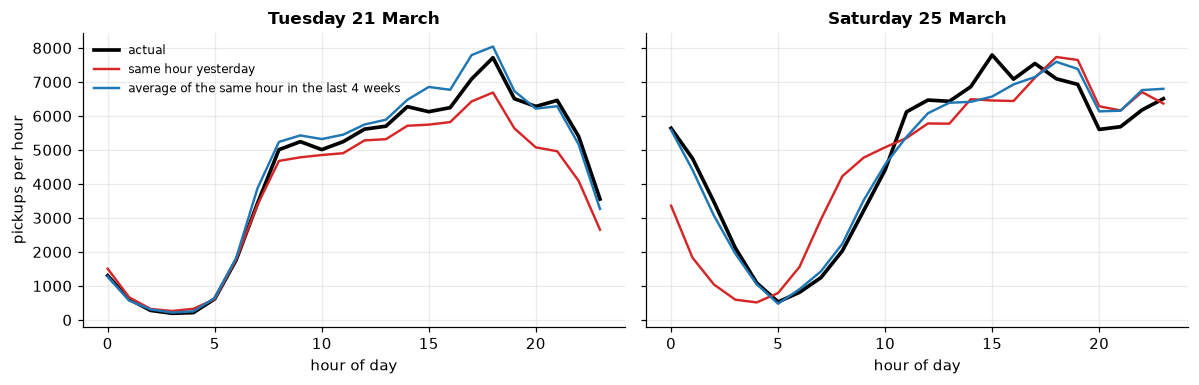

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, day in zip(axes, ["2023-03-21", "2023-03-25"]):
    sub = {name: bt[bt["origin"] == day] for name, bt in runs.items()}
    actual = sub[best_baseline]
    ax.plot(actual["step"] - 1, actual["actual"], "k", lw=2.4, label="actual")
    for name, color in [("seasonal naive: same hour yesterday", "tab:red"), (best_baseline, "tab:blue")]:
        ax.plot(sub[name]["step"] - 1, sub[name]["forecast"], color=color, lw=1.6, label=name.split(": ")[-1])
    ax.set(title=pd.Timestamp(day).strftime("%A %d %B"), xlabel="hour of day")
axes[0].set_ylabel("pickups per hour"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

On the Tuesday both forecasts have the right shape, but "same hour yesterday" runs low all day, because it copies a Monday and Mondays are quieter. On the Saturday it is wrong in *shape*: it copies a Friday, which has quiet small hours, while a Saturday starts the day still busy with people coming home from Friday night, and the morning ramp arrives later. The four-week average, which has seen several Saturdays, tracks the curve closely.

## 2. Where does "same hour yesterday" go wrong?

Break its error down by the weekday being forecast. Each forecast copies the day before, so Monday is forecast from Sunday, Saturday from Friday, and so on.

In [6]:
bt = runs["seasonal naive: same hour yesterday"].assign(abs_error=lambda d: (d["actual"] - d["forecast"]).abs())
by_origin_day = bt.groupby(bt["origin"].dt.day_name())["abs_error"].mean().round(0)
by_origin_day.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).to_frame("MAE when forecasting that weekday").T

origin,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
MAE when forecasting that weekday,"1,251.00",549.00,265.00,356.00,574.00,"1,004.00",931.00


**Monday** (copying a Sunday), **Saturday** (copying a Friday) and **Sunday** (copying a Saturday) are the worst, with errors of 900 to 1,250; Wednesday and Thursday, which copy a similar weekday, are the best at about 270 to 360. Forecasting a Monday from a Sunday, or a Saturday from a Friday, copies the *wrong kind of day*. Errors are not spread evenly: they concentrate at the **transitions** of the weekly cycle. That is also the best argument for always reporting error broken down by something meaningful (weekday, hour, season) rather than one average.

## 3. Tuning a baseline, honestly

"Average of the last *k* weeks": what should *k* be? The tempting move is to try every *k* on the test window and keep the best. That is **tuning on the test set**, and the number you report is then optimistic. The honest way: pick *k* on a **validation window** that comes *before* the test window, then report the test score once.

The validation window is the two weeks just before the test: 4 to 17 March.

In [7]:
val_origins = fc.rolling_origins(y.index, first_origin="2023-03-04", last_origin="2023-03-17")
before_val = y[:"2023-03-03"]

rows = []
for k in range(1, 9):
    f = lambda hist, idx, k=k: fc.seasonal_mean(hist, idx, weeks=k)
    rows.append({"weeks averaged (k)": k,
                 "validation MAE": fc.score(fc.backtest(y, f, origins=val_origins, horizon=HORIZON), before_val)["MAE"],
                 "test MAE": fc.score(fc.backtest(y, f, origins=test_origins, horizon=HORIZON), train)["MAE"]})
tune = pd.DataFrame(rows).set_index("weeks averaged (k)")
chosen_on_validation = tune["validation MAE"].idxmin()
best_on_test = tune["test MAE"].idxmin()
print(f"best k on the validation window: {chosen_on_validation}  ->  its test MAE: {tune.loc[chosen_on_validation, 'test MAE']:,.0f}")
print(f"best k on the test window:       {best_on_test}  ->  its test MAE: {tune.loc[best_on_test, 'test MAE']:,.0f}")
tune.round(0).astype(int).T

best k on the validation window: 1  ->  its test MAE: 372
best k on the test window:       8  ->  its test MAE: 255


weeks averaged (k),1,2,3,4,5,6,7,8
validation MAE,283,298,311,316,321,329,336,346
test MAE,372,318,296,277,261,262,257,255


The two windows **disagree completely**. On the validation fortnight, the shortest memory wins (k = 1) and longer averages get steadily worse; on the test fortnight the opposite happens (longer is better, and k = 1 is the worst of all). Demand was drifting upward through March, which rewards recent weeks in one window, while in the other the single week we copy from happens to be an unusual one.

Three lessons:

1. **A choice made on one window may not carry to the next.** If we had used k = 1 as chosen on validation we would have scored about 370 on the test, worse than every longer average. This is why a single holdout is fragile, and the backtesting page uses many windows.
2. **Do not pick k on the test window** and then quote its score. Here it would have given the flattering figure of about 255, which the validation procedure would never have found.
3. The curve is **flat from k = 4 to 8** on the test window, within about 10%. When the differences are that small compared with the window-to-window noise, choosing a middle value (4) and moving on is the sensible response.

## 4. When is the baseline wrong?

A final look at the best baseline: its absolute error by **hour of day** (averaged over the 14 test days).

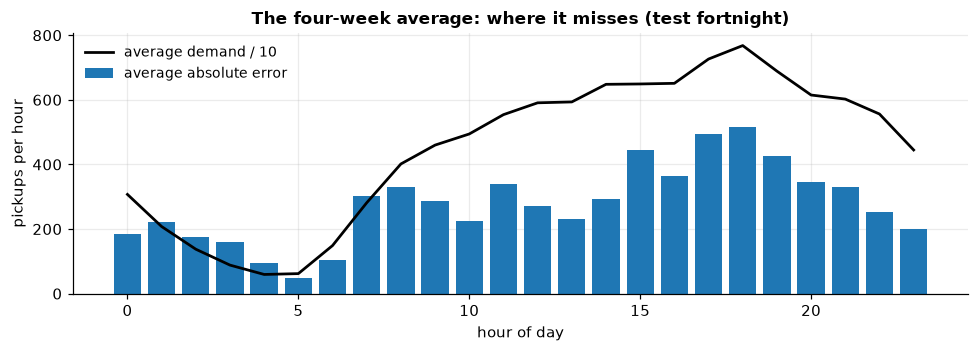

worst hours: {18: 515.0, 17: 494.0, 15: 443.0} | quietest-hours error: {4: 95.0, 5: 49.0, 6: 105.0}


In [8]:
bt = runs[best_baseline].assign(abs_error=lambda d: (d["actual"] - d["forecast"]).abs(), hour=lambda d: d["time"].dt.hour)
hourly_error = bt.groupby("hour").agg(MAE=("abs_error", "mean"), mean_demand=("actual", "mean"))

fig, ax = plt.subplots(figsize=(9, 3.3))
ax.bar(hourly_error.index, hourly_error["MAE"], color="tab:blue", label="average absolute error")
ax.plot(hourly_error.index, hourly_error["mean_demand"] / 10, "k", lw=1.8, label="average demand / 10")
ax.set(xlabel="hour of day", ylabel="pickups per hour", title="The four-week average: where it misses (test fortnight)"); ax.legend()
plt.tight_layout(); plt.show()
print("worst hours:", hourly_error["MAE"].nlargest(3).round(0).to_dict(), "| quietest-hours error:", hourly_error["MAE"].loc[4:6].round(0).to_dict())

The absolute error is largest in the **evening peak** (5 to 7pm, about 430 to 520 pickups) and smallest at 4 to 6am (about 50 to 105). That is natural: more demand means more room to be wrong in absolute terms. But *relative* to demand the picture flips: at 2 to 4am the error is 13 to 18% of the demand, against about 5% in the middle of the day. That is exactly the trap in percentage errors, discussed on the metrics page.

<div class="admonition tip">
<p class="admonition-title">The baseline is a deliverable, not a formality</p>
<p>Keep the baseline in the project forever. It is the line every later model is measured against, and the fallback when a model breaks. If your model beats it by a little, say so honestly: the cost of running a complex model has to be paid for.</p>
</div>

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| "Naive" forecast has a huge error | wrong baseline for a seasonal series | use *seasonal* naive with the right period |
| Great test score after trying many settings | tuned on the test window | choose settings on a validation window before the test |
| Best setting differs between windows | few windows, drift | evaluate on many origins; prefer a flat region of the curve |
| One bad week hurts "last week" forecast | a single week is noisy | average several weeks (or take the median) |
| One average error hides the pattern | errors cluster at weekday and hour transitions | always break error down by weekday and hour |

## Check yourself

<details class="question">
<summary>1. What does a MASE of 0.80 for the four-week average tell you, and what would 1.00 mean?</summary>

The model's mean absolute error is **80% of** the error that the "same hour last week" forecast made on the training data. So it is 20% better than that reference. A value of 1.00 would mean no better than that reference, and a value above 1 would mean worse. MASE is useful because it needs no division by the (possibly near-zero) actual values and it compares series of very different sizes.

</details>

<details class="question">
<summary>2. The seasonal-naive-168 forecast scores MASE 1.08 on the test fortnight although MASE is defined relative to its own training error. Is the test period harder than the training period?</summary>

Slightly, or about the same: 1.08 says its test error is 8% larger than its in-sample error scaled the same way. The test fortnight is **not** much harder than the training period, so differences between models there are not an artefact of an unusually difficult stretch. A value far from 1 for the reference baseline itself would be a warning that the test window is unrepresentative.

</details>

<details class="question">
<summary>3. A teammate reports: ‘I tried 20 smoothing settings and the best one scores 240 on the test fortnight, beating the baseline’s 277.’ What is wrong with that claim?</summary>

The best of 20 attempts is selected **using the test data**, so its score is optimistically biased, as the table above showed (255 chosen on test versus 372 for the value validation picked). The fix is to choose among the 20 settings on a validation window and report the single chosen setting on the test, ideally across several test windows. Even a real improvement of about 13% needs that protocol to be believable.

</details>

## Exercises

<details class="question">
<summary>Replace the mean with the <em>median</em> of the last 4 weeks (<code>statistic='median'</code>). Predict first: better, worse, or the same? Then compare the scores.</summary>

```python
f = lambda hist, idx: fc.seasonal_mean(hist, idx, weeks=4, statistic="median")
print(fc.score(fc.backtest(y, f, origins=test_origins, horizon=HORIZON), train))
```

On these data the median and the mean give the same score to the nearest pickup (about 277). The median helps when one of the four weeks is badly off (a snowstorm or a holiday); here the test fortnight had no such week, so there is nothing for it to protect against. It would matter for a window containing a public holiday.

</details>

<details class="question">
<summary>Build a <em>profile</em> baseline: forecast each hour with the all-history mean for that weekday and hour. How does it compare with the four-week average? Why might it not do better, given it uses more data?</summary>

```python
def profile(hist, idx):
    g = hist.groupby([hist.index.dayofweek, hist.index.hour]).mean()
    return pd.Series([g[(t.dayofweek, t.hour)] for t in idx], index=idx)
print(fc.score(fc.backtest(y, profile, origins=test_origins, horizon=HORIZON), train)["MAE"])
```

It scores about 282, practically the same as the four-week average (277). More data does not help much because the level **drifts** (about 11% higher in March than in January, as the previous page showed), so old weeks are slightly out of date. A real model must be able to follow the level, not just the shape.

</details>

<details class="question">
<summary>For the naive (last value) forecast, how does the average error change with how far ahead we predict (step 1 to 24)? Why is it not a steadily rising line?</summary>

```python
bt = runs["naive: repeat the last value"]
print(bt.assign(e=(bt.actual - bt.forecast).abs()).groupby("step")["e"].mean().round(0).tolist())
```

The error is about 1,400 at step 1 and rises to nearly 3,900 at steps 5 and 6 (4am and 5am), then falls to about 2,100 to 2,500 across the middle of the day, climbs again to about 3,500 at step 19 (6pm) and ends near 1,200 at step 24. The forecast is stuck at the 11pm level, which is fairly busy, so it overshoots badly when demand bottoms out at 4 to 5am and undershoots in the evening peak; it is nearly right only where the daily curve happens to cross that level. The error follows the daily cycle, not the horizon.

</details>

## Recap

- Test forecasts with a **rolling origin**: at each origin, only the past is visible. Report an average over many origins.
- **Seasonal naive** (same hour last week) and a **multi-week seasonal average** are strong baselines for strongly seasonal series. Plain naive is only right for series without a cycle.
- Here the four-week average gets about 280 pickups of error (MASE 0.80), the number every model must beat.
- Do not tune on the test window: choose settings on an earlier validation window. One validation window can still mislead, which motivates backtesting over many windows.
- Break errors down by weekday and hour: they cluster at the transitions.

**Next:** *Classical models: exponential smoothing and ARIMA*.